# Problema 4 — Clusterização Musical: Criando a Playlist Perfeita

**Integrante:** Gean Carlos

## Objetivo

Aplicar um algoritmo de aprendizado não supervisionado para agrupar músicas com base em suas características acústicas, criando cinco grupos que possam representar diferentes estilos de experiência musical.

O trabalho inclui a limpeza dos dados, a análise da correlação entre energia e acústica, o treinamento do algoritmo de clusterização e a avaliação qualitativa de um dos grupos formados.

### Questão 1 — Análise das colunas textuais

O conjunto de dados possui colunas textuais que ajudam a identificar as músicas e interpretar os resultados da análise.

- **`track_name`:** representa o nome da música. Essa coluna permite identificar as faixas e compreender quais músicas foram agrupadas pelo algoritmo.
- **`artists`:** contém o nome do artista ou dos artistas responsáveis pela música. Essa informação ajuda a reconhecer e interpretar os resultados da clusterização.
- **`track_id`:** é um identificador utilizado para distinguir as músicas no conjunto de dados. Ele também pode auxiliar na identificação de registros duplicados.

Essas colunas são importantes para a identificação e interpretação dos resultados, mas não foram utilizadas diretamente no treinamento do K-Means. O algoritmo foi aplicado às características musicais numéricas e categóricas, como energia, dançabilidade e acousticness, para agrupar as músicas de acordo com suas propriedades sonoras.

Dessa forma, foi possível utilizar os nomes das músicas e dos artistas para analisar os grupos encontrados sem permitir que os textos de identificação influenciassem diretamente a formação dos clusters.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

# Reprodutibilidade dos experimentos
RANDOM_STATE = 42

# Exibição de gráficos dentro do notebook
%matplotlib inline

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [ ]:
from google.colab import files

uploaded = files.upload()

# Obtém o nome do arquivo CSV enviado
arquivo = next(
    nome for nome in uploaded
    if nome.lower().endswith(".csv")
)

df = pd.read_csv(arquivo)

print("Dimensões do dataset:", df.shape)

display(df.head())

print("\nTipos das colunas:")
display(df.dtypes.to_frame("tipo"))

print("\nValores ausentes por coluna:")
display(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame("valores_ausentes")
)

Saving dataset.csv to dataset (1).csv
Dimensões do dataset: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic



Tipos das colunas:


,tipo
Unnamed: 0,int64
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64



Valores ausentes por coluna:


,valores_ausentes
artists,1
track_name,1
album_name,1
Unnamed: 0,0
track_id,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


In [ ]:
# 1. Verificar se existem IDs de músicas repetidos
print("Total de registros:", len(df))
print("IDs únicos:", df["track_id"].nunique())
print("IDs ausentes:", df["track_id"].isna().sum())
print("Linhas completamente duplicadas:", df.duplicated().sum())

# 2. Verificar registros sem nome ou artista
print("\nRegistros sem nome da música:")
display(df[df["track_name"].isna()].head())

print("\nRegistros sem nome do artista:")
display(df[df["artists"].isna()].head())

# 3. Verificar valores ausentes nas variáveis numéricas
colunas_numericas = df.select_dtypes(include="number").columns

display(
    df[colunas_numericas]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("valores_ausentes")
)

Total de registros: 114000
IDs únicos: 89741
IDs ausentes: 0
Linhas completamente duplicadas: 0

Registros sem nome da música:


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop



Registros sem nome do artista:


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


,valores_ausentes
Unnamed: 0,0
popularity,0
duration_ms,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0


In [ ]:
# Criar uma cópia para preservar o dataset original
df_limpo = df.copy()

# Remover coluna de índice exportada para o CSV, se existir
if "Unnamed: 0" in df_limpo.columns:
    df_limpo = df_limpo.drop(columns=["Unnamed: 0"])

# Remover registros sem identificação da música ou artista
df_limpo = df_limpo.dropna(
    subset=["track_name", "artists", "track_id"]
)

# Manter apenas uma ocorrência de cada música
df_limpo = df_limpo.drop_duplicates(
    subset=["track_id"],
    keep="first"
)

# Conferir o resultado
print("Registros após a limpeza:", len(df_limpo))
print("IDs únicos:", df_limpo["track_id"].nunique())
print("Nomes de músicas ausentes:", df_limpo["track_name"].isna().sum())
print("Artistas ausentes:", df_limpo["artists"].isna().sum())
print("IDs duplicados restantes:", df_limpo["track_id"].duplicated().sum())

display(df_limpo.head())

Registros após a limpeza: 89740
IDs únicos: 89740
Nomes de músicas ausentes: 0
Artistas ausentes: 0
IDs duplicados restantes: 0


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Correlação entre energy e acousticness: -0.7326


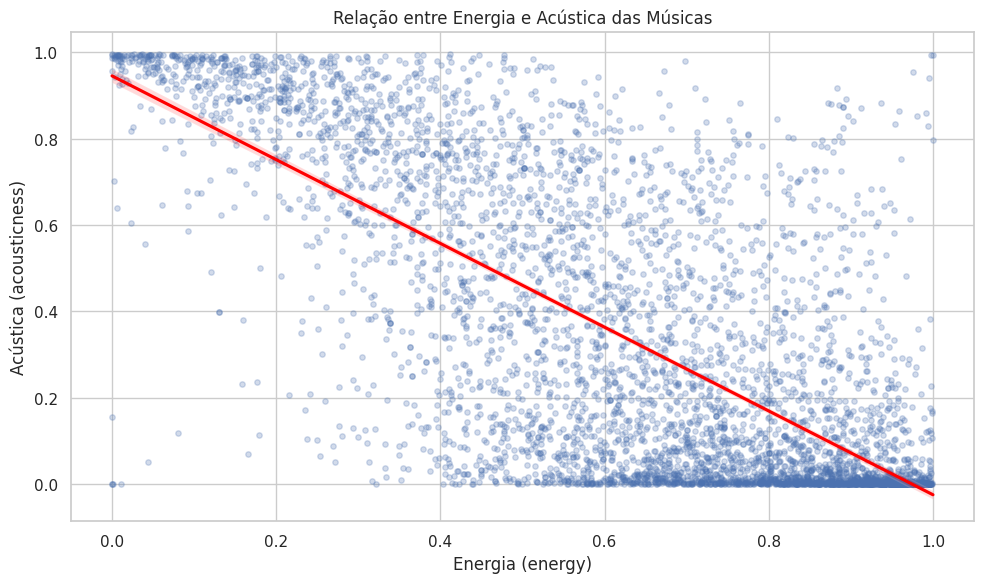

In [ ]:
# Calcular a correlação de Pearson
correlacao = df_limpo["energy"].corr(
    df_limpo["acousticness"],
    method="pearson"
)

print(f"Correlação entre energy e acousticness: {correlacao:.4f}")

# Usar uma amostra apenas para deixar o gráfico mais leve
amostra_grafico = df_limpo.sample(
    n=min(5000, len(df_limpo)),
    random_state=42
)

# Criar o gráfico de dispersão
plt.figure(figsize=(10, 6))

sns.regplot(
    data=amostra_grafico,
    x="energy",
    y="acousticness",
    scatter_kws={"alpha": 0.25, "s": 15},
    line_kws={"color": "red"}
)

plt.title("Relação entre Energia e Acústica das Músicas")
plt.xlabel("Energia (energy)")
plt.ylabel("Acústica (acousticness)")
plt.tight_layout()
plt.show()

### Questão 2 — Análise de Correlação Acústica

Foi calculado o coeficiente de correlação de Pearson entre as variáveis `energy` e `acousticness` do conjunto de dados após a limpeza. O resultado obtido foi de **−0,7326**, indicando uma correlação linear negativa forte.

Esse resultado demonstra que, no conjunto de dados analisado, músicas com maior energia tendem a apresentar menor valor de acústica. No contexto musical, isso sugere uma tendência de oposição entre a intensidade percebida das faixas e suas características acústicas.

O gráfico de dispersão reforça essa tendência por meio da linha de regressão descendente. Entretanto, existem exceções, pois as duas características não apresentam uma relação perfeitamente linear. Além disso, correlação não implica causalidade.

Essa análise contribui para compreender como as características musicais se relacionam antes da aplicação do algoritmo de clusterização.

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

# Features acústicas numéricas
features_numericas = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "liveness",
    "speechiness",
    "valence",
    "tempo",
    "loudness"
]

# Features categóricas relacionadas às características musicais
features_categoricas = [
    "key",
    "mode",
    "time_signature"
]

# Preservar os dados de identificação para interpretar os clusters depois
colunas_identificacao = [
    "track_id",
    "track_name",
    "artists",
    "album_name"
]

# Criar a tabela de identificação, mantendo o índice original
df_musicas = df_limpo[colunas_identificacao].copy()

# Selecionar somente as features autorizadas para o modelo
X = df_limpo[features_numericas + features_categoricas].copy()

# Garantir que as colunas numéricas sejam numéricas
X[features_numericas] = X[features_numericas].apply(
    pd.to_numeric,
    errors="coerce"
)

# Tratar valores ausentes que eventualmente existam nas features
# Neste dataset, a inspeção anterior não indicou ausências numéricas.
# A mediana é usada como proteção para possíveis valores ausentes.
X[features_numericas] = X[features_numericas].fillna(
    X[features_numericas].median()
)

# Converter as variáveis categóricas para texto,
# para que o codificador as trate como categorias
for coluna in features_categoricas:
    X[coluna] = X[coluna].fillna("desconhecido").astype(str)

# Pré-processamento: padronização + codificação categórica
preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), features_numericas),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            features_categoricas
        )
    ]
)

# Transformar as features para a representação que o K-Means utilizará
X_preparado = preprocessador.fit_transform(X)

print("Quantidade de músicas:", len(X))
print("Quantidade de features numéricas:", len(features_numericas))
print("Quantidade de features categóricas:", len(features_categoricas))
print("Dimensão após o pré-processamento:", X_preparado.shape)

Quantidade de músicas: 89740
Quantidade de features numéricas: 9
Quantidade de features categóricas: 3
Dimensão após o pré-processamento: (89740, 28)


In [ ]:
# Criar o modelo com exatamente cinco clusters
modelo_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Treinar e atribuir um cluster a cada música
clusters = modelo_kmeans.fit_predict(X_preparado)

# Guardar o resultado junto aos dados de identificação
df_resultados = df_musicas.copy()
df_resultados["cluster"] = clusters

# Mostrar a quantidade de músicas em cada cluster
print("Quantidade de músicas em cada cluster:")
display(
    df_resultados["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("quantidade_musicas")
)

print("\nPrimeiras músicas com seus clusters:")
display(
    df_resultados[
        ["track_name", "artists", "cluster"]
    ].head(10)
)

Quantidade de músicas em cada cluster:


,quantidade_musicas
cluster,
0,33712
1,26822
2,7335
3,1105
4,20766



Primeiras músicas com seus clusters:


,track_name,artists,cluster
0,Comedy,Gen Hoshino,0
1,Ghost - Acoustic,Ben Woodward,4
2,To Begin Again,Ingrid Michaelson;ZAYN,4
3,Can't Help Falling In Love,Kina Grannis,4
4,Hold On,Chord Overstreet,4
5,Days I Will Remember,Tyrone Wells,0
6,Say Something,A Great Big World;Christina Aguilera,4
7,I'm Yours,Jason Mraz,0
8,Lucky,Jason Mraz;Colbie Caillat,0
9,Hunger,Ross Copperman,4


Perfil acústico médio de cada cluster:


,danceability,energy,acousticness,instrumentalness,liveness,speechiness,valence,tempo,loudness
cluster,,,,,,,,,
0,0.693,0.730,0.207,0.065,0.193,0.093,0.692,120.582,-6.543
1,0.476,0.821,0.068,0.239,0.264,0.084,0.322,136.180,-5.993
2,0.352,0.198,0.822,0.776,0.173,0.052,0.178,103.017,-20.699
3,0.573,0.674,0.729,0.008,0.664,0.825,0.449,101.795,-11.072
4,0.535,0.392,0.667,0.060,0.186,0.056,0.404,114.018,-10.465


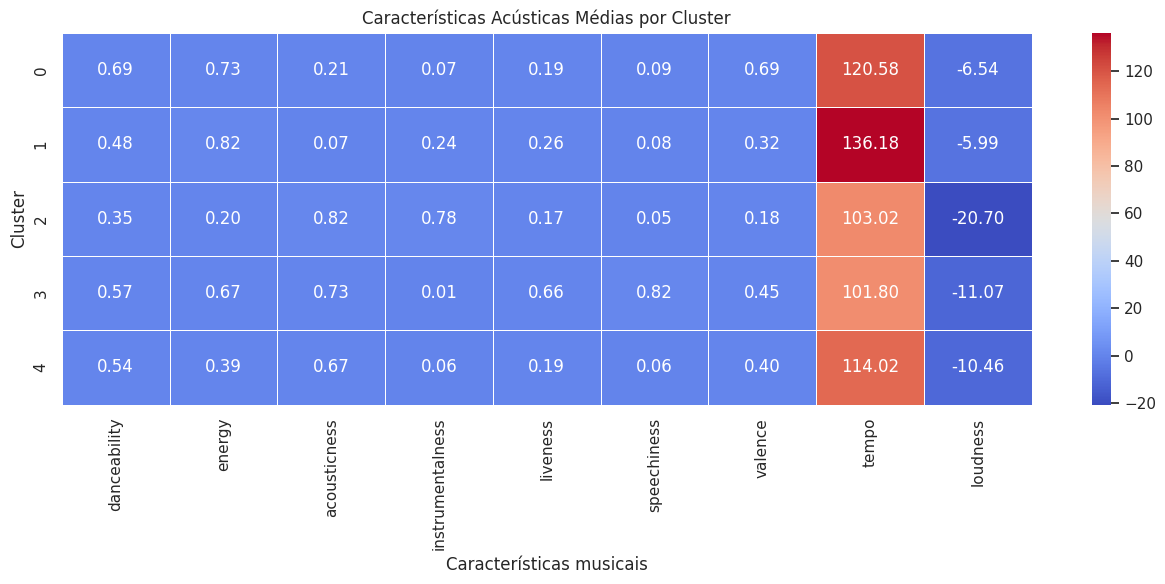

In [ ]:
# Associar os clusters às músicas originais
df_analise = df_limpo.copy()
df_analise["cluster"] = clusters

# Calcular o perfil médio de cada cluster
perfil_clusters = (
    df_analise
    .groupby("cluster")[features_numericas]
    .mean()
    .round(3)
)

print("Perfil acústico médio de cada cluster:")
display(perfil_clusters)

# Visualizar os perfis em um mapa de calor
plt.figure(figsize=(13, 6))

sns.heatmap(
    perfil_clusters,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Características Acústicas Médias por Cluster")
plt.xlabel("Características musicais")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

### Questão 3 — Aplicação do algoritmo de clusterização

Para agrupar as músicas de acordo com suas características sonoras, foi utilizado o algoritmo **K-Means**, uma técnica de aprendizado não supervisionado que identifica grupos de registros com características semelhantes, sem precisar de rótulos previamente definidos.

O modelo foi configurado para formar cinco clusters, conforme solicitado na atividade. Foram utilizadas nove características numéricas — danceability, energy, acousticness, instrumentalness, liveness, speechiness, valence, tempo e loudness — e três características categóricas — key, mode e time_signature.

Durante o pré-processamento, as características numéricas foram padronizadas com `StandardScaler`, enquanto as categóricas foram transformadas em representações numéricas por meio de `OneHotEncoder`. As colunas de identificação das músicas foram preservadas para a interpretação dos resultados, mas não foram utilizadas no treinamento. A coluna `track_genre` também foi excluída para que o agrupamento fosse baseado nas características musicais, e não no gênero informado.

Após a execução do algoritmo, as 89.740 músicas foram distribuídas entre cinco clusters:

- **Cluster 0:** 33.712 músicas.
- **Cluster 1:** 26.822 músicas.
- **Cluster 2:** 7.335 músicas.
- **Cluster 3:** 1.105 músicas.
- **Cluster 4:** 20.766 músicas.

Os grupos apresentaram quantidades diferentes de músicas, indicando que o algoritmo identificou agrupamentos de tamanhos distintos conforme as características utilizadas. A análise das características médias de cada cluster permite compreender melhor os perfis musicais encontrados e avaliar sua utilidade na criação automática de playlists.

In [ ]:

cluster_escolhido = 4

musicas_cluster = df_analise[
    df_analise["cluster"] == cluster_escolhido
]

cinco_musicas = musicas_cluster.sample(
    n=5,
    random_state=42
)

colunas_exibicao = [
    "track_name",
    "artists",
    "energy",
    "acousticness",
    "danceability",
    "valence"
]

print("Cinco músicas selecionadas do cluster", cluster_escolhido)
display(cinco_musicas[colunas_exibicao])

print("\nPerfil médio do cluster:")
display(
    musicas_cluster[
        ["energy", "acousticness", "danceability", "valence"]
    ].mean().to_frame("Média").round(3)
)


Cinco músicas selecionadas do cluster 4


,track_name,artists,energy,acousticness,danceability,valence
105045,Payday,Crate Diggers,0.447,0.875,0.696,0.461
76774,Rondine al nido - Live,Luciano Pavarotti;Andrea Griminelli;Orchestra ...,0.345,0.974,0.240,0.173
26885,Trettifyran,Per Myrberg,0.470,0.693,0.629,0.920
52235,Someday You'll Call My Name,Hank Williams;Drifting Cowboys,0.240,0.955,0.527,0.400
9086,Acaso Não Sabeis - Ao Vivo,Colo de Deus,0.555,0.685,0.358,0.277



Perfil médio do cluster:


,Média
energy,0.392
acousticness,0.667
danceability,0.535
valence,0.404


### Questão 4 — Análise de um cluster musical

Foram selecionadas cinco músicas pertencentes ao cluster 4, gerado pelo algoritmo K-Means. Entre elas estão *Payday*, *Rondine al nido - Live*, *Trettifyran*, *Someday You'll Call My Name* e *Acaso Não Sabeis - Ao Vivo*.

O cluster apresentou médias de 0,392 para energia, 0,667 para acousticness, 0,535 para danceability e 0,404 para valence. Esses resultados indicam uma tendência a músicas com menor intensidade energética e características acústicas mais elevadas.

Consideramos que o agrupamento faz sentido parcialmente, pois as cinco músicas apresentam características acústicas relativamente altas, embora existam diferenças de energia, dançabilidade e valência. Isso demonstra que o algoritmo consegue reunir músicas com algumas propriedades semelhantes, mas não garante que todas tenham o mesmo estilo ou transmitam a mesma sensação ao ouvinte.

Concluímos que a clusterização pode auxiliar na criação automática de playlists por características sonoras. Entretanto, uma avaliação auditiva das músicas seria importante para verificar se o agrupamento também faz sentido na experiência real de escuta.